<br><br>

# Лабораторная работа №2

## Autoencoder и Variational Autoencoder на наборе данных MNIST

<br>

| | |
|---|---|
| **Выполнил** | Цурцурика Илья |
| **Группа** | IASD2501 |
| **Дата** | 28.09.2026 |

<br>

---

## 1. Цель и задача

**Цель:** реализовать, обучить и сравнить две архитектуры типа encoder-decoder — классический Autoencoder (AE) и Variational Autoencoder (VAE) — на наборе данных MNIST для **сжатия, реконструкции и генерации** изображений.

**Задача:** построить две модели с одинаковым "скелетом" и сравнить их поведение по четырём направлениям:

1. качество реконструкции при разных размерах латентного кода;
2. устройство латентного пространства;
3. способность генерировать новые цифры;
4. плавность переходов между объектами (интерполяция).

## 2. Теория (кратко)

**Autoencoder.** Encoder $f$ переводит вход $x\in\mathbb{R}^{784}$ в латентный вектор $z=f(x)$ меньшей размерности, decoder $g$ восстанавливает $\hat{x}=g(z)$. Обучение минимизирует ошибку реконструкции. Ключевой элемент — *bottleneck* (размер $z$ гораздо меньше размера входа), он заставляет сеть учить компактное представление. Для одного $x$ код $z$ — **одна точка**.

**Variational Autoencoder.** Encoder выдаёт не точку, а параметры распределения $q(z\mid x)=\mathcal{N}(\mu,\sigma^2)$. Вектор $z$ выбирается случайно с помощью *трюка репараметризации*:

$$z=\mu+\sigma\odot\varepsilon,\qquad \varepsilon\sim\mathcal{N}(0,I),$$

благодаря чему градиент проходит через операцию сэмплирования. Функция потерь:

$$\mathcal{L}_{VAE}=\underbrace{\mathrm{BCE}(x,\hat{x})}_{\text{реконструкция}}+\underbrace{D_{KL}\big(q(z\mid x)\,\|\,\mathcal{N}(0,I)\big)}_{\text{регуляризация}},\qquad D_{KL}=-\tfrac12\sum_j\big(1+\log\sigma_j^2-\mu_j^2-\sigma_j^2\big).$$

KL-слагаемое притягивает распределения всех объектов к $\mathcal{N}(0,I)$, поэтому для генерации достаточно взять $z\sim\mathcal{N}(0,I)$ и пропустить через decoder.

| | Autoencoder | VAE |
|---|---|---|
| Латентное представление | точка $z$ | распределение $(\mu,\sigma)$ |
| Функция потерь | BCE | BCE + KL |
| Что оптимизируется | только реконструкция | реконструкция + структура латентного пространства |
| Генерация | нет заданного распределения для $z$ | $z\sim\mathcal{N}(0,I)$ |

## 3. Условия эксперимента

| Параметр | Значение |
|---|---|
| Данные | MNIST (torchvision): 60 000 обучающих и 10 000 тестовых изображений 28x28, пиксели в [0, 1], вход - вектор из 784 значений |
| Среда | Google Colab, PyTorch |
| Оптимизатор | Adam, lr = 1e-3 |
| Batch size | 256 (`drop_last=True`) |
| Число эпох | 30 |
| Функция потерь реконструкции | Binary Cross-Entropy |
| Размеры латентного кода | **2** (для прямой визуализации), **8, 16, 64** (как в лекции) |
| Начальное значение генератора случайных чисел | `torch.manual_seed(0)` |
| Метрики | BCE (на изображение, сумма по пикселям) и MSE (на пиксель) на **тестовой** выборке |

Для VAE при оценке на тесте реконструкция строится по $\mu$ (без случайного шума), поэтому сравнение с AE честное.

**Архитектура** (одинаковая у обеих моделей, различается только способ получения кода):

- Encoder: 784 -> 512 -> 256 (ReLU), затем
  - AE: линейный слой 256 -> d;
  - VAE: два линейных слоя 256 -> d (для mu и log(sigma^2)).
- Decoder: d -> 256 -> 512 -> 784, ReLU в скрытых слоях, Sigmoid на выходе.

## 4. Реализация

Класс `Autoencoder`, класс `VAE` и функции потерь. Полный скрипт обучения (`train.py`) находится в ноутбуке `Lab2_AE_VAE_MNIST.ipynb`, использованном для запуска.

In [ ]:
"""
data_utils.py
Загрузка датасета MNIST и подготовка DataLoader'ов для PyTorch.

Основной вариант — стандартный:
    torchvision.datasets.MNIST(root=..., download=True)
(используйте его, если у вас есть доступ в интернет к серверам Torch/AWS).

В данном окружении вместо этого используется .npz-архив с уже
нормализованными изображениями (пиксели в диапазоне [0, 1]).
Функция load_mnist_npz универсальна и будет работать с любым
.npz-файлом, содержащим ключи training_images/training_labels/
test_images/test_labels.
"""

import numpy as np
import torch
from torch.utils.data import TensorDataset, DataLoader


def load_mnist_npz(path: str):
    """Загружает MNIST из .npz-файла и возвращает тензоры (X_train, y_train, X_test, y_test).

    X имеет форму (N, 784) с float32 значениями в [0, 1].
    y имеет форму (N,) — целочисленные метки классов (0..9).
    """
    data = np.load(path)

    x_train = data["training_images"].reshape(-1, 784).astype("float32")
    y_train = data["training_labels"].reshape(-1, 10).argmax(axis=1).astype("int64")

    x_test = data["test_images"].reshape(-1, 784).astype("float32")
    y_test = data["test_labels"].reshape(-1, 10).argmax(axis=1).astype("int64")

    return (
        torch.from_numpy(x_train),
        torch.from_numpy(y_train),
        torch.from_numpy(x_test),
        torch.from_numpy(y_test),
    )


def get_dataloaders(npz_path: str, batch_size: int = 256):
    """Возвращает (train_loader, test_loader, X_test, y_test)."""
    x_train, y_train, x_test, y_test = load_mnist_npz(npz_path)

    train_ds = TensorDataset(x_train, y_train)
    test_ds = TensorDataset(x_test, y_test)

    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True, drop_last=True)
    test_loader = DataLoader(test_ds, batch_size=batch_size, shuffle=False)

    return train_loader, test_loader, x_test, y_test


In [ ]:
"""
models.py
Две архитектуры encoder-decoder для MNIST:

  1) Autoencoder (AE)  — детерминированное сжатие в точку латентного пространства.
  2) Variational Autoencoder (VAE) — сжатие в распределение (mu, log_var),
     из которого сэмплируется точка через reparameterization trick.

Обе модели используют одинаковую "скелетную" архитектуру полносвязных
слоёв, чтобы сравнение было корректным: отличие — только в способе
формирования латентного кода и в функции потерь.
"""

import torch
import torch.nn as nn
import torch.nn.functional as F

INPUT_DIM = 784
HIDDEN_DIMS = (512, 256)


# --------------------------------------------------------------------------- #
#  1. Классический Autoencoder
# --------------------------------------------------------------------------- #
class Autoencoder(nn.Module):
    def __init__(self, latent_dim: int = 2):
        super().__init__()
        h1, h2 = HIDDEN_DIMS

        self.encoder = nn.Sequential(
            nn.Linear(INPUT_DIM, h1), nn.ReLU(),
            nn.Linear(h1, h2), nn.ReLU(),
            nn.Linear(h2, latent_dim),           # прямое отображение в точку z
        )

        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, h2), nn.ReLU(),
            nn.Linear(h2, h1), nn.ReLU(),
            nn.Linear(h1, INPUT_DIM), nn.Sigmoid(),
        )

    def encode(self, x):
        return self.encoder(x)

    def decode(self, z):
        return self.decoder(z)

    def forward(self, x):
        z = self.encode(x)
        x_hat = self.decode(z)
        return x_hat, z


def ae_loss(x_hat, x):
    """Простая реконструкционная ошибка (Binary Cross-Entropy по пикселям)."""
    return F.binary_cross_entropy(x_hat, x, reduction="sum") / x.size(0)


# --------------------------------------------------------------------------- #
#  2. Variational Autoencoder
# --------------------------------------------------------------------------- #
class VAE(nn.Module):
    def __init__(self, latent_dim: int = 2):
        super().__init__()
        h1, h2 = HIDDEN_DIMS
        self.latent_dim = latent_dim

        self.encoder_body = nn.Sequential(
            nn.Linear(INPUT_DIM, h1), nn.ReLU(),
            nn.Linear(h1, h2), nn.ReLU(),
        )
        self.fc_mu = nn.Linear(h2, latent_dim)
        self.fc_logvar = nn.Linear(h2, latent_dim)

        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, h2), nn.ReLU(),
            nn.Linear(h2, h1), nn.ReLU(),
            nn.Linear(h1, INPUT_DIM), nn.Sigmoid(),
        )

    def encode(self, x):
        h = self.encoder_body(x)
        return self.fc_mu(h), self.fc_logvar(h)

    @staticmethod
    def reparameterize(mu, logvar):
        """z = mu + sigma * eps,  eps ~ N(0, I)  — 'трюк репараметризации',
        позволяющий обратно распространять градиент через операцию сэмплирования."""
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std

    def decode(self, z):
        return self.decoder(z)

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        x_hat = self.decode(z)
        return x_hat, mu, logvar, z


def vae_loss(x_hat, x, mu, logvar):
    """ELBO (Evidence Lower BOund), которую максимизируем -> минимизируем -ELBO:

        L = Recon_loss(x, x_hat) + KL( q(z|x) || N(0, I) )

    Recon_loss — насколько хорошо декодер восстанавливает вход (BCE).
    KL-слагаемое "подтягивает" апостериорное распределение q(z|x) к
    стандартному нормальному N(0, I), что и делает латентное пространство
    непрерывным и пригодным для генерации новых образцов.
    """
    recon = F.binary_cross_entropy(x_hat, x, reduction="sum") / x.size(0)
    kld = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp()) / x.size(0)
    return recon + kld, recon, kld

Число параметров моделей (различие между AE и VAE - только дополнительный линейный слой для log(sigma^2)):

In [ ]:
for d in (2, 8, 16, 64):
    n_ae = sum(p.numel() for p in Autoencoder(d).parameters())
    n_vae = sum(p.numel() for p in VAE(d).parameters())
    print(f"{d:>3}   {n_ae:>10,}   {n_vae:>10,}")

dim   AE, параметров   VAE, параметров
  2        1 068 306         1 068 820
  8        1 071 384         1 073 440
 16        1 075 488         1 079 600
 64        1 100 112         1 116 560

In [ ]:
"""
train.py  (версия 2)
Обучает AE и VAE на MNIST для нескольких размеров латентного кода (по лекции: 8, 16, 64
+ dim=2 для прямой визуализации), считает метрики на ТЕСТОВОЙ выборке и строит графики:

  reconstructions.png   оригинал / AE / VAE для dim = 8, 16, 64
  latent_space.png      dim=2: латентное пространство AE vs VAE + t-SNE для dim=16
  manifold.png          dim=2: декодирование регулярной сетки z
  samples.png           генерация новых цифр: AE (z~N(0,I)), AE (z~гауссиана по данным), VAE (z~N(0,I))
  interpolation.png     интерполяция между двумя цифрами в латентном пространстве
  loss_curves.png       кривые обучения (dim=16)
  test_metrics.png/json метрики BCE и MSE на тесте для всех dim

Параметры как в лекции: Adam, lr=1e-3, batch=256, 30 эпох, BCE.
"""
import os, json
import numpy as np
import torch, torch.optim as optim
import torch.nn.functional as F
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE

from data_utils import get_dataloaders
from models import Autoencoder, VAE, ae_loss, vae_loss

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
NPZ_PATH = "/home/claude/data/mnist.npz"
OUT_DIR = "/mnt/user-data/outputs"
DIMS = [2, 8, 16, 64]
EPOCHS, BATCH_SIZE, LR = 30, 256, 1e-3
torch.manual_seed(0); np.random.seed(0)
os.makedirs(OUT_DIR, exist_ok=True)


def train_ae(loader, dim):
    m = Autoencoder(dim).to(DEVICE); opt = optim.Adam(m.parameters(), lr=LR); hist = []
    for ep in range(EPOCHS):
        tot = 0.0
        for x, _ in loader:
            x = x.to(DEVICE); opt.zero_grad()
            loss = ae_loss(m(x)[0], x); loss.backward(); opt.step(); tot += loss.item()
        hist.append(tot / len(loader))
    print(f"[AE  dim={dim:2d}] final train loss={hist[-1]:.2f}", flush=True)
    return m, hist


def train_vae(loader, dim):
    m = VAE(dim).to(DEVICE); opt = optim.Adam(m.parameters(), lr=LR)
    hist, hr, hk = [], [], []
    for ep in range(EPOCHS):
        t = r = k = 0.0
        for x, _ in loader:
            x = x.to(DEVICE); opt.zero_grad()
            xh, mu, lv, _ = m(x)
            loss, rec, kl = vae_loss(xh, x, mu, lv); loss.backward(); opt.step()
            t += loss.item(); r += rec.item(); k += kl.item()
        n = len(loader); hist.append(t / n); hr.append(r / n); hk.append(k / n)
    print(f"[VAE dim={dim:2d}] final train loss={hist[-1]:.2f} (recon={hr[-1]:.2f}, KL={hk[-1]:.2f})", flush=True)
    return m, (hist, hr, hk)


@torch.no_grad()
def evaluate(ae, vae, x_test):
    """Метрики на тесте. Для VAE реконструкция делается по mu (детерминированно)."""
    ae.eval(); vae.eval(); x = x_test.to(DEVICE)
    xa = ae(x)[0]
    xv = vae.decode(vae.encode(x)[0])
    f = lambda xh: (F.binary_cross_entropy(xh, x, reduction="sum").item() / len(x),
                    F.mse_loss(xh, x).item())
    (ba, ma), (bv, mv) = f(xa), f(xv)
    return {"AE_bce": ba, "AE_mse": ma, "VAE_bce": bv, "VAE_mse": mv}


def show(ax, img):
    ax.imshow(img.reshape(28, 28), cmap="gray"); ax.axis("off")


@torch.no_grad()
def fig_reconstructions(models, x_test, n=10):
    rows = [("Оригинал", x_test[:n].numpy())]
    for d in (8, 16, 64):
        ae, vae = models[d]; x = x_test[:n].to(DEVICE)
        rows.append((f"AE d={d}", ae(x)[0].cpu().numpy()))
    for d in (8, 16, 64):
        ae, vae = models[d]; x = x_test[:n].to(DEVICE)
        rows.append((f"VAE d={d}", vae.decode(vae.encode(x)[0]).cpu().numpy()))
    fig, axes = plt.subplots(len(rows), n, figsize=(n * 1.0, len(rows) * 1.05))
    for r, (name, imgs) in enumerate(rows):
        for i in range(n):
            show(axes[r, i], imgs[i])
        axes[r, 0].text(-0.15, 0.5, name, transform=axes[r, 0].transAxes, ha="right", va="center", fontsize=9)
    fig.suptitle("Реконструкции при разных размерах латентного кода", y=0.995)
    fig.savefig(f"{OUT_DIR}/reconstructions.png", dpi=150, bbox_inches="tight"); plt.close(fig)


@torch.no_grad()
def fig_latent(models, x_test, y_test, n=4000):
    ae2, vae2 = models[2]; x = x_test[:n].to(DEVICE); lab = y_test[:n].numpy()
    ae16, vae16 = models[16]
    panels = [("AE, dim=2", ae2.encode(x).cpu().numpy()),
              ("VAE, dim=2 (μ)", vae2.encode(x)[0].cpu().numpy())]
    fig, axes = plt.subplots(1, 4, figsize=(20, 4.8))
    for ax, (t, z) in zip(axes[:2], panels):
        sc = ax.scatter(z[:, 0], z[:, 1], c=lab, cmap="tab10", s=4, alpha=.7); ax.set_title(t)
    for ax, (t, z) in zip(axes[2:], [("AE, dim=16 → t-SNE", ae16.encode(x).cpu().numpy()),
                                     ("VAE, dim=16 (μ) → t-SNE", vae16.encode(x)[0].cpu().numpy())]):
        e = TSNE(n_components=2, init="pca", random_state=0).fit_transform(z[:2000])
        ax.scatter(e[:, 0], e[:, 1], c=lab[:2000], cmap="tab10", s=4, alpha=.7); ax.set_title(t)
    fig.colorbar(sc, ax=axes, label="Цифра", fraction=0.015)
    fig.savefig(f"{OUT_DIR}/latent_space.png", dpi=130, bbox_inches="tight"); plt.close(fig)


@torch.no_grad()
def fig_manifold(models, g=12, span=3.0):
    ae, vae = models[2]; lin = np.linspace(-span, span, g)
    cv = {k: np.zeros((28 * g, 28 * g)) for k in ("ae", "vae")}
    for i, yi in enumerate(lin):
        for j, xi in enumerate(lin):
            z = torch.tensor([[xi, yi]], dtype=torch.float32).to(DEVICE)
            cv["ae"][i*28:(i+1)*28, j*28:(j+1)*28] = ae.decode(z).cpu().numpy().reshape(28, 28)
            cv["vae"][i*28:(i+1)*28, j*28:(j+1)*28] = vae.decode(z).cpu().numpy().reshape(28, 28)
    fig, axes = plt.subplots(1, 2, figsize=(11, 5.5))
    for ax, k, t in zip(axes, ("ae", "vae"), ("AE: сетка z ∈ [-3,3]²", "VAE: сетка z ∈ [-3,3]²")):
        ax.imshow(cv[k], cmap="gray"); ax.set_title(t); ax.axis("off")
    fig.savefig(f"{OUT_DIR}/manifold.png", dpi=140, bbox_inches="tight"); plt.close(fig)


@torch.no_grad()
def fig_samples(models, x_train, d=16, n=64):
    ae, vae = models[d]
    zt = ae.encode(x_train[:10000].to(DEVICE)); mu, sd = zt.mean(0), zt.std(0)
    z_std = torch.randn(n, d, device=DEVICE)
    z_fit = mu + sd * torch.randn(n, d, device=DEVICE)
    sets = [("AE: z ~ N(0, I)", ae.decode(z_std)),
            ("AE: z ~ гауссиана, подогнанная\nпод коды обучающих данных", ae.decode(z_fit)),
            ("VAE: z ~ N(0, I)", vae.decode(z_std))]
    fig, axes = plt.subplots(1, 3, figsize=(15, 5.4))
    for ax, (t, imgs) in zip(axes, sets):
        grid = imgs.cpu().numpy().reshape(8, 8, 28, 28).transpose(0, 2, 1, 3).reshape(8 * 28, 8 * 28)
        ax.imshow(grid, cmap="gray"); ax.set_title(t); ax.axis("off")
    fig.suptitle(f"Генерация новых цифр (dim={d}, случайные z)")
    fig.savefig(f"{OUT_DIR}/samples.png", dpi=140, bbox_inches="tight"); plt.close(fig)


@torch.no_grad()
def fig_interp(models, x_test, y_test, d=16, steps=10, pairs=((0, 1), (2, 3))):
    ae, vae = models[d]; ts = torch.linspace(0, 1, steps, device=DEVICE).unsqueeze(1)
    # выбираем пары разных цифр
    idx = []
    for a, b in ((3, 8), (1, 7), (0, 6)):
        idx.append((int((y_test == a).nonzero()[0]), int((y_test == b).nonzero()[0])))
    fig, axes = plt.subplots(2 * len(idx), steps, figsize=(steps * 1.0, 2 * len(idx) * 1.05))
    for p, (i, j) in enumerate(idx):
        xa, xb = x_test[i:i+1].to(DEVICE), x_test[j:j+1].to(DEVICE)
        za, zb = ae.encode(xa), ae.encode(xb)
        ma, mb = vae.encode(xa)[0], vae.encode(xb)[0]
        ia = ae.decode((1 - ts) * za + ts * zb).cpu().numpy()
        iv = vae.decode((1 - ts) * ma + ts * mb).cpu().numpy()
        for s in range(steps):
            show(axes[2*p, s], ia[s]); show(axes[2*p+1, s], iv[s])
        axes[2*p, 0].text(-0.15, .5, "AE", transform=axes[2*p, 0].transAxes, ha="right", va="center")
        axes[2*p+1, 0].text(-0.15, .5, "VAE", transform=axes[2*p+1, 0].transAxes, ha="right", va="center")
    fig.suptitle(f"Линейная интерполяция в латентном пространстве (dim={d})", y=0.995)
    fig.savefig(f"{OUT_DIR}/interpolation.png", dpi=140, bbox_inches="tight"); plt.close(fig)


def fig_losses(ae_h, vae_h):
    hist, hr, hk = vae_h
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    axes[0].plot(ae_h, label="AE (BCE)"); axes[0].plot(hr, label="VAE: реконструкция (BCE)")
    axes[0].plot(hist, label="VAE: полный loss = BCE + KL")
    axes[0].set_title("Обучение, dim=16"); axes[0].set_xlabel("Эпоха"); axes[0].legend()
    axes[1].plot(hk, color="C3"); axes[1].set_title("VAE: KL-дивергенция, dim=16"); axes[1].set_xlabel("Эпоха")
    fig.tight_layout(); fig.savefig(f"{OUT_DIR}/loss_curves.png", dpi=140, bbox_inches="tight"); plt.close(fig)


def fig_metrics(metrics):
    fig, axes = plt.subplots(1, 2, figsize=(11, 4)); w = 0.38; xs = np.arange(len(DIMS))
    for ax, key, t in zip(axes, ("bce", "mse"), ("BCE на тесте (на изображение)", "MSE на тесте (на пиксель)")):
        ax.bar(xs - w/2, [metrics[d][f"AE_{key}"] for d in DIMS], w, label="AE")
        ax.bar(xs + w/2, [metrics[d][f"VAE_{key}"] for d in DIMS], w, label="VAE")
        ax.set_xticks(xs); ax.set_xticklabels([f"dim={d}" for d in DIMS]); ax.set_title(t); ax.legend()
    fig.tight_layout(); fig.savefig(f"{OUT_DIR}/test_metrics.png", dpi=140, bbox_inches="tight"); plt.close(fig)


if __name__ == "__main__":
    train_loader, _, x_test, y_test = get_dataloaders(NPZ_PATH, BATCH_SIZE)
    x_train = train_loader.dataset.tensors[0]
    models, metrics, hist16 = {}, {}, None
    for d in DIMS:
        ae, ah = train_ae(train_loader, d)
        vae, vh = train_vae(train_loader, d)
        models[d] = (ae, vae); metrics[d] = evaluate(ae, vae, x_test)
        if d == 16: hist16 = (ah, vh)
        print(f"   test dim={d}: {metrics[d]}", flush=True)
    json.dump(metrics, open(f"{OUT_DIR}/test_metrics.json", "w"), indent=2)
    fig_reconstructions(models, x_test); fig_latent(models, x_test, y_test)
    fig_manifold(models); fig_samples(models, x_train); fig_interp(models, x_test, y_test)
    fig_losses(*hist16); fig_metrics(metrics)
    for d in (2, 16):
        torch.save(models[d][0].state_dict(), f"{OUT_DIR}/ae_dim{d}.pt")
        torch.save(models[d][1].state_dict(), f"{OUT_DIR}/vae_dim{d}.pt")
    print("DONE")


## 5. Результаты

### 5.1 Динамика обучения (dim = 16)

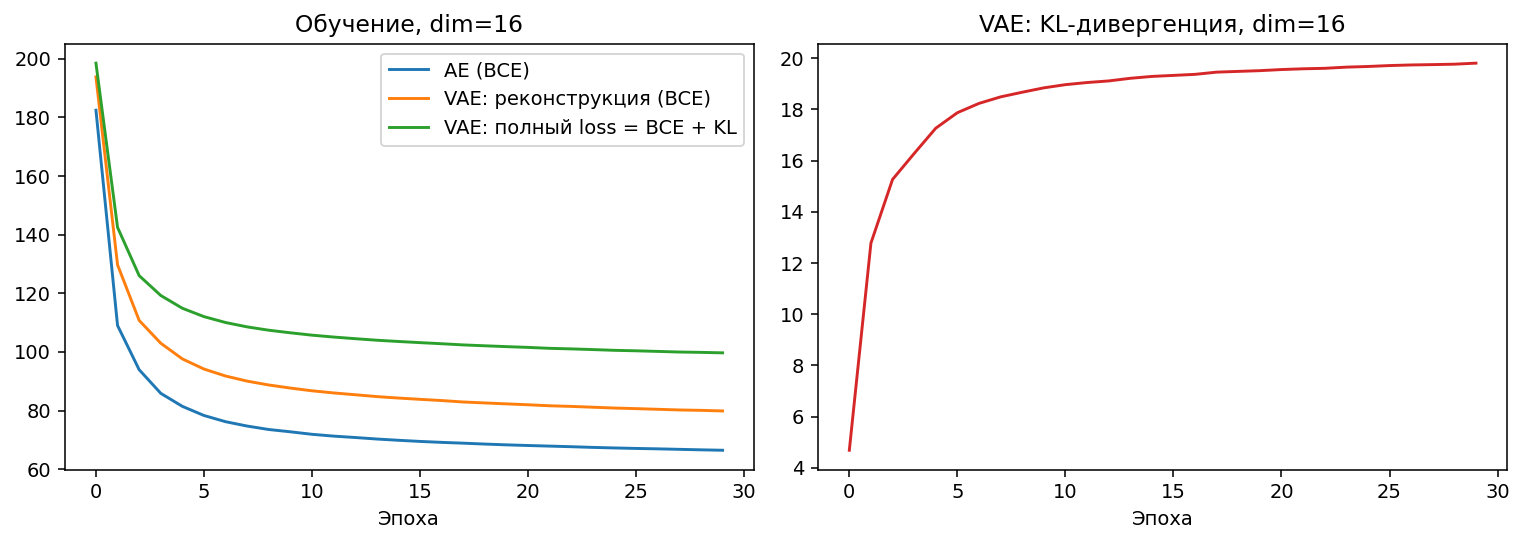

По графику: BCE у AE к концу обучения ~66, у VAE реконструкционная часть ~80, полный loss ~100 (реконструкция + KL). KL-дивергенция быстро растёт за первые 5 эпох и выходит на плато около 20. Кривые монотонно убывают, признаков расходимости нет.

Замечание: обучающие значения VAE считаются со случайным z, а тестовые метрики ниже - по mu, поэтому напрямую сравнивать их между собой нельзя.

### 5.2 Метрики на тестовой выборке

| dim | Сжатие | AE BCE | VAE BCE | AE MSE | VAE MSE |
|---|---|---|---|---|---|
| 2 | 392× | 132.4 | 133.8 | 0.0357 | 0.0363 |
| 8 | 98× | 84.5 | 84.4 | 0.0150 | 0.0151 |
| 16 | 49× | 67.7 | 75.9 | 0.0082 | 0.0115 |
| 64 | 12× | 58.0 | 75.1 | 0.0044 | 0.0112 |

BCE - на изображение, MSE - на пиксель; чем меньше, тем лучше.

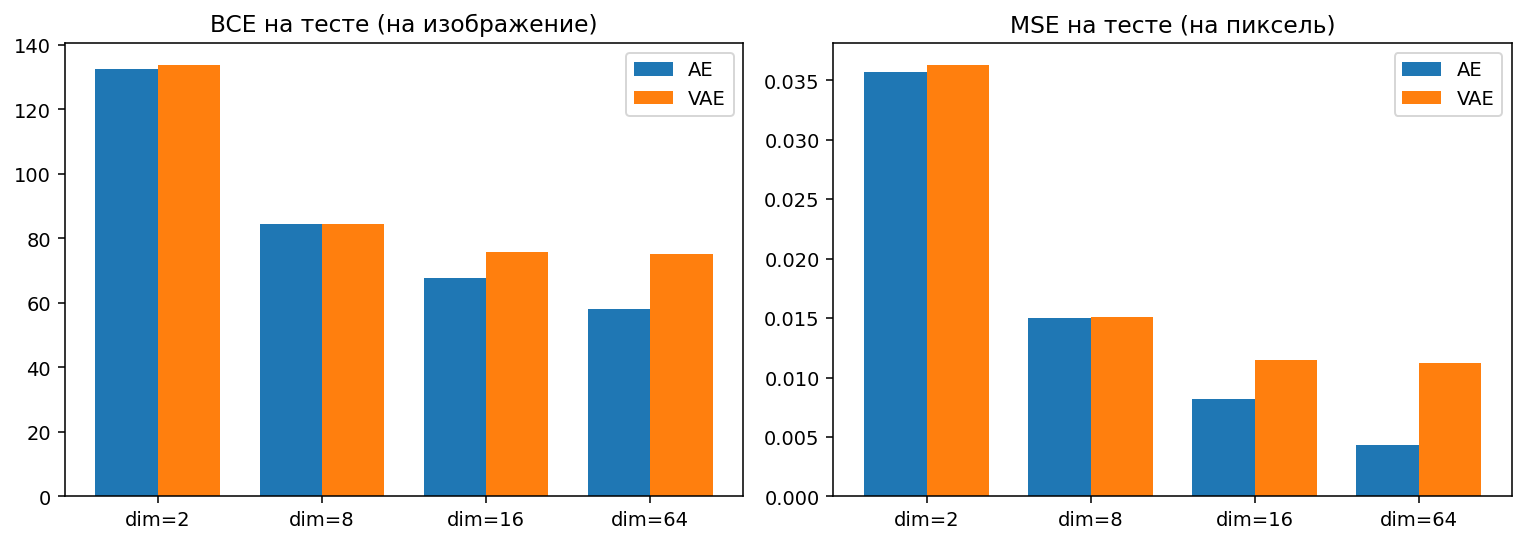

Разница между моделями в числах (степень сжатия = 784 / dim; delta BCE = VAE - AE):

In [ ]:
m = {
    2:  dict(AE_bce=132.362925,   AE_mse=0.035697, VAE_bce=133.81135,   VAE_mse=0.036310),
    8:  dict(AE_bce=84.4526875,   AE_mse=0.015013, VAE_bce=84.3905875,  VAE_mse=0.015059),
    16: dict(AE_bce=67.6924125,   AE_mse=0.008215, VAE_bce=75.8531375,  VAE_mse=0.011491),
    64: dict(AE_bce=57.99403125,  AE_mse=0.004356, VAE_bce=75.07448125, VAE_mse=0.011222),
}
for d, v in m.items():
    print(f"dim={d:>2}  сжатие {784/d:6.1f}x  AE_BCE={v['AE_bce']:6.2f}  VAE_BCE={v['VAE_bce']:6.2f}  "
          f"deltaBCE={v['VAE_bce']-v['AE_bce']:6.2f}  MSE VAE/AE={v['VAE_mse']/v['AE_mse']:.2f}x")

dim= 2  сжатие  392.0x  AE_BCE=132.36  VAE_BCE=133.81  deltaBCE=  1.45  MSE VAE/AE=1.02x
dim= 8  сжатие   98.0x  AE_BCE= 84.45  VAE_BCE= 84.39  deltaBCE= -0.06  MSE VAE/AE=1.00x
dim=16  сжатие   49.0x  AE_BCE= 67.69  VAE_BCE= 75.85  deltaBCE=  8.16  MSE VAE/AE=1.40x
dim=64  сжатие   12.2x  AE_BCE= 57.99  VAE_BCE= 75.07  deltaBCE= 17.08  MSE VAE/AE=2.58x

**Наблюдения.**

1. Чем больше размер кода, тем лучше реконструкция. У AE BCE падает от 132,4 (dim = 2) до 58,0 (dim = 64).
2. При dim = 2 и 8 обе модели практически неразличимы (разница в BCE 1,4 и 0,06; это в пределах того, что можно списать на случайность одного запуска).
3. При dim = 16 и 64 AE заметно лучше: BCE меньше на 8,2 и 17,1, а MSE у VAE выше в 1,4 и 2,6 раза.
4. У VAE ошибка почти не улучшается при переходе 16 -> 64 (75,9 -> 75,1), тогда как у AE улучшение большое (67,7 -> 58,0). Возможное объяснение: KL-штраф ограничивает информацию, которую можно передать через код. Это гипотеза, в работе она не проверялась (для проверки можно посчитать дисперсию mu по каждому измерению z).

### 5.3 Реконструкция

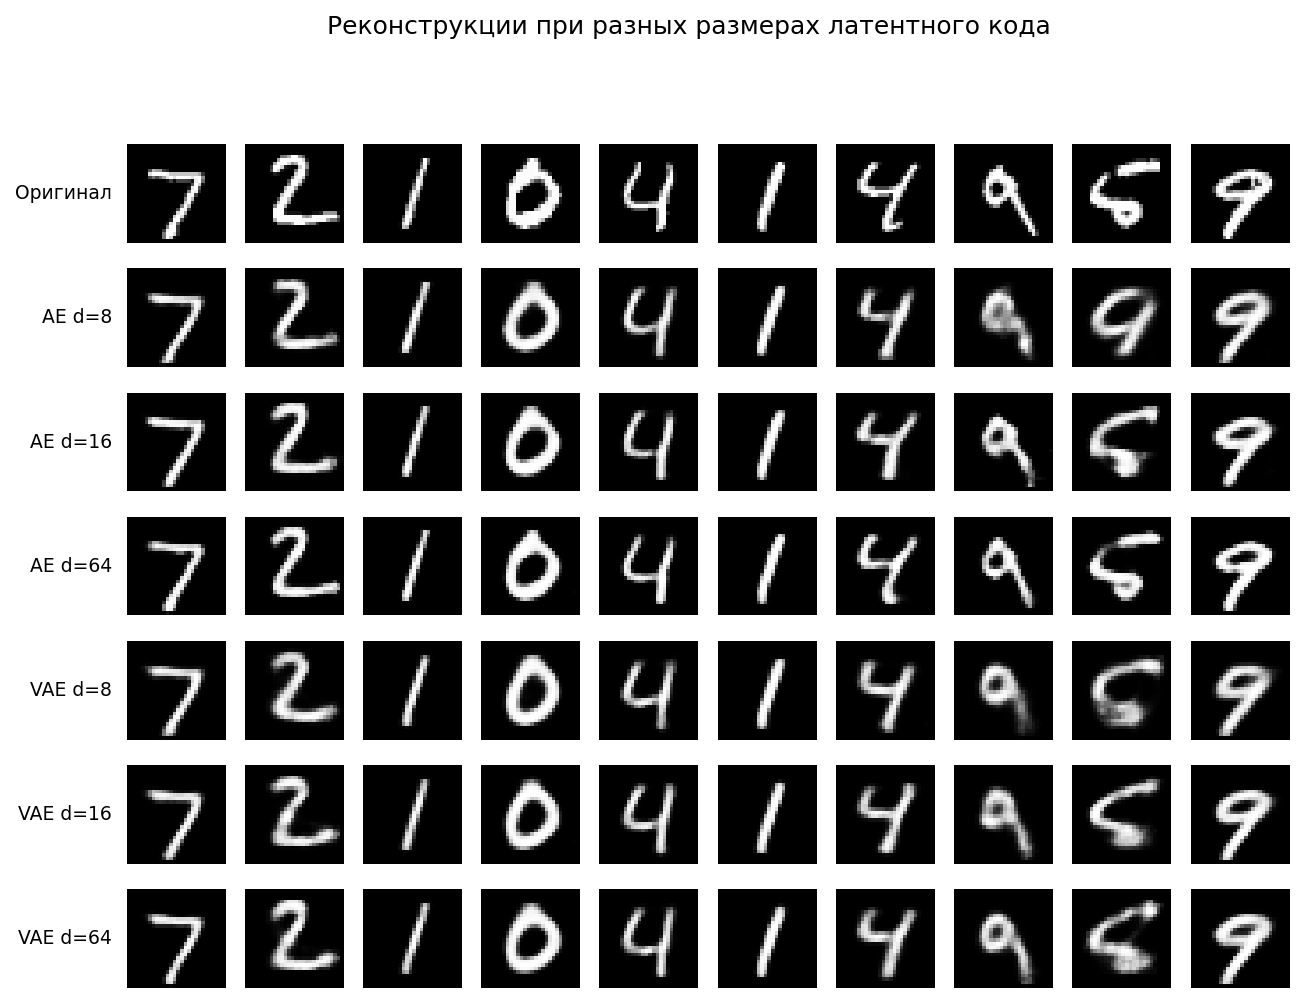

Верхняя строка - оригиналы (первые 10 тестовых изображений), далее AE и VAE с кодом 8, 16, 64.

- Простые цифры (1, 0, 7, 2) восстанавливаются хорошо уже при dim = 8.
- Сложные образцы (последняя "5", "9" с петлёй) при dim = 8 размыты у обеих моделей. При dim = 16-64 AE передаёт форму лучше, VAE даёт более сглаженные, "усреднённые" образы. Это согласуется с таблицей метрик.

### 5.4 Латентное пространство

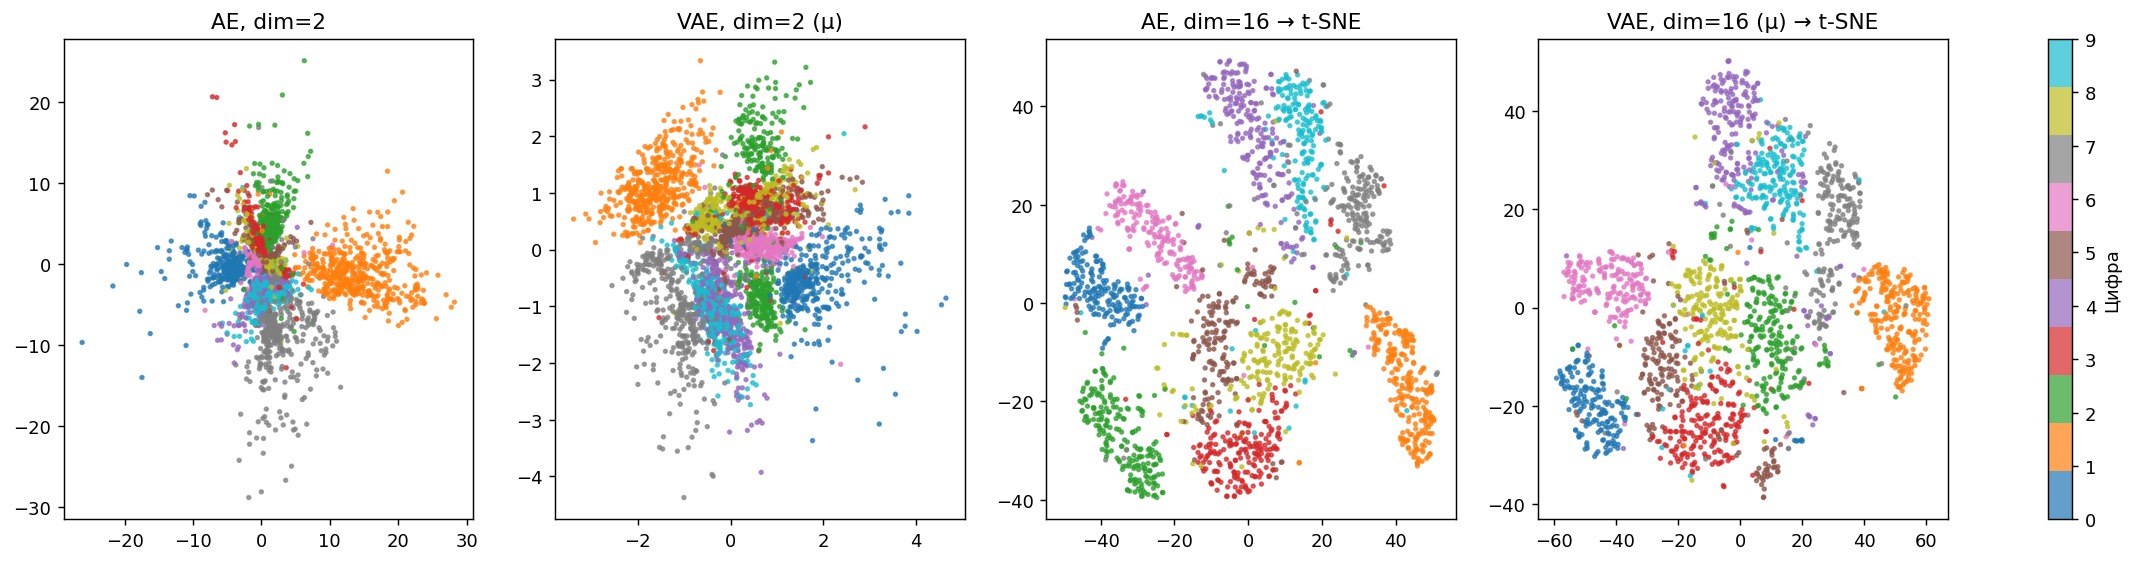

Слева направо: AE и VAE при dim = 2 (точки - коды 4000 тестовых изображений, цвет - цифра), затем AE и VAE при dim = 16, спроецированные на плоскость методом t-SNE (2000 изображений).

- **AE, dim = 2:** облака классов вытянуты "лучами" от центра, диапазон значений достигает +-30, между лучами широкие пустые области.
- **VAE, dim = 2:** все коды лежат в компактной области примерно +-4 вокруг нуля, то есть в области, для которой обучена регуляризация N(0, I). Классы перекрываются сильнее, но пустот меньше.
- **dim = 16 (t-SNE):** обе модели образуют чёткие кластеры по цифрам, пересечения есть у похожих классов (4/9, 3/5/8). То есть AE тоже даёт полезное представление для классификации или кластеризации. Различие AE и VAE не в разделимости классов, а в масштабе и "заполненности" пространства.

### 5.5 Генерация новых цифр

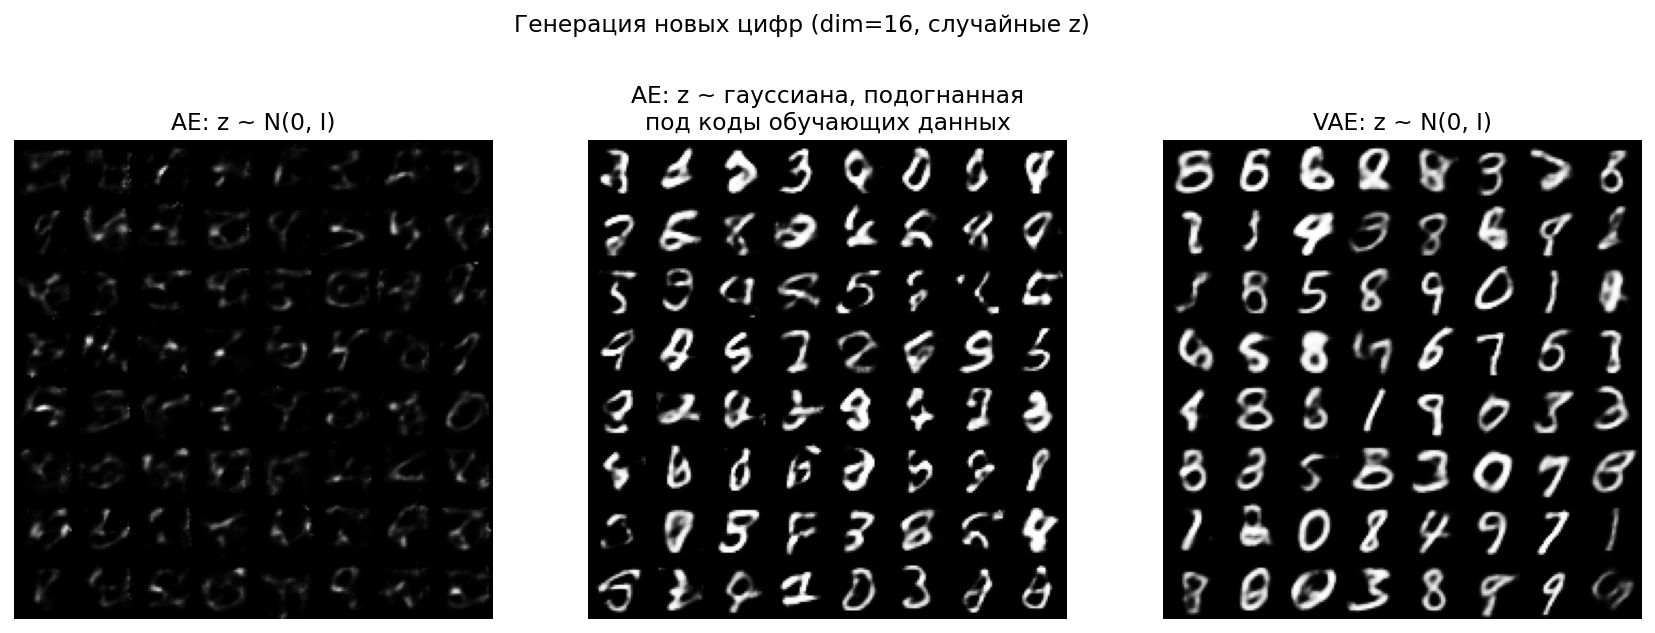

64 случайных вектора z при dim = 16, пропущенные через decoder:

- **AE, z ~ N(0, I):** бледные штрихи, на цифры не похожи. Коды AE лежат в области другого масштаба, поэтому стандартное нормальное распределение для него не подходит.
- **AE, z из гауссианы, подогнанной под коды обучающих данных:** цифры узнаются, но много "ломаных" и шумных образцов.
- **VAE, z ~ N(0, I):** в основном узнаваемые цифры без какой-либо подгонки, часть образцов размыта.

Вывод: AE можно превратить в генератор, если знать распределение его кодов, но у VAE это распределение задано в самой постановке обучения.

### 5.6 Декодирование сетки в латентном пространстве (dim = 2)

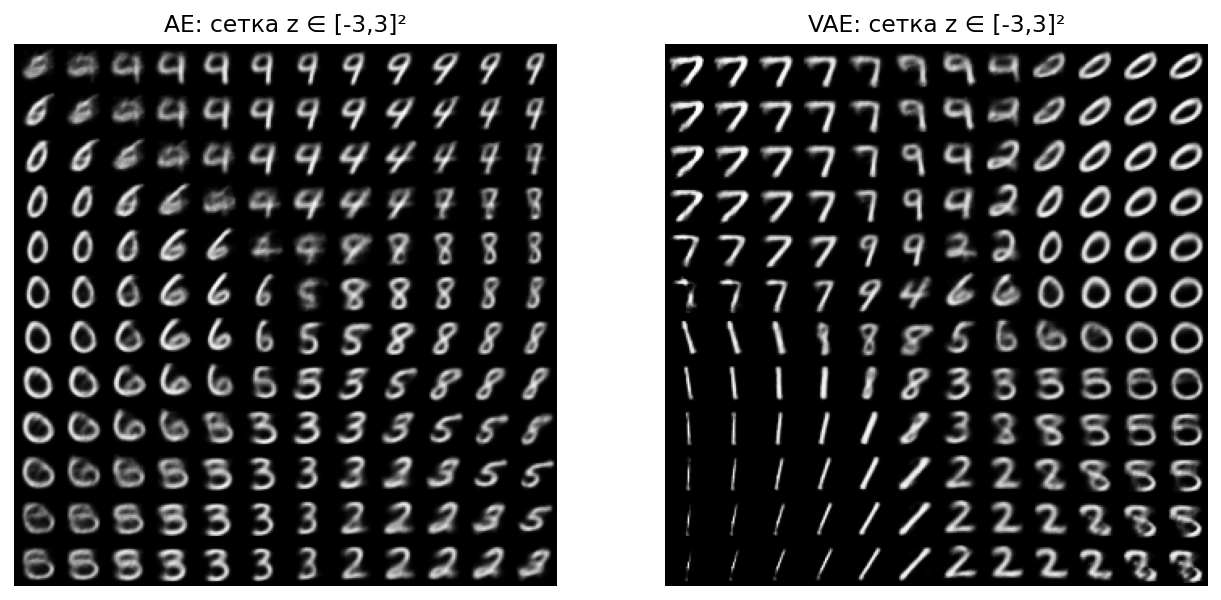

Сетка 12x12 точек z в [-3,3]^2 декодируется в изображения.

- Оба decoder-а выдают узнаваемые цифры (0, 2, 3, 5, 6, 8, 9 и другие) с плавными переходами между ними.
- У AE часть ячеек размыта (верхний левый угол смешивает 9, 4 и 6). У VAE в той же области больше разных чётких цифр, потому что коды VAE сосредоточены именно в этом диапазоне.

### 5.7 Интерполяция (dim = 16)

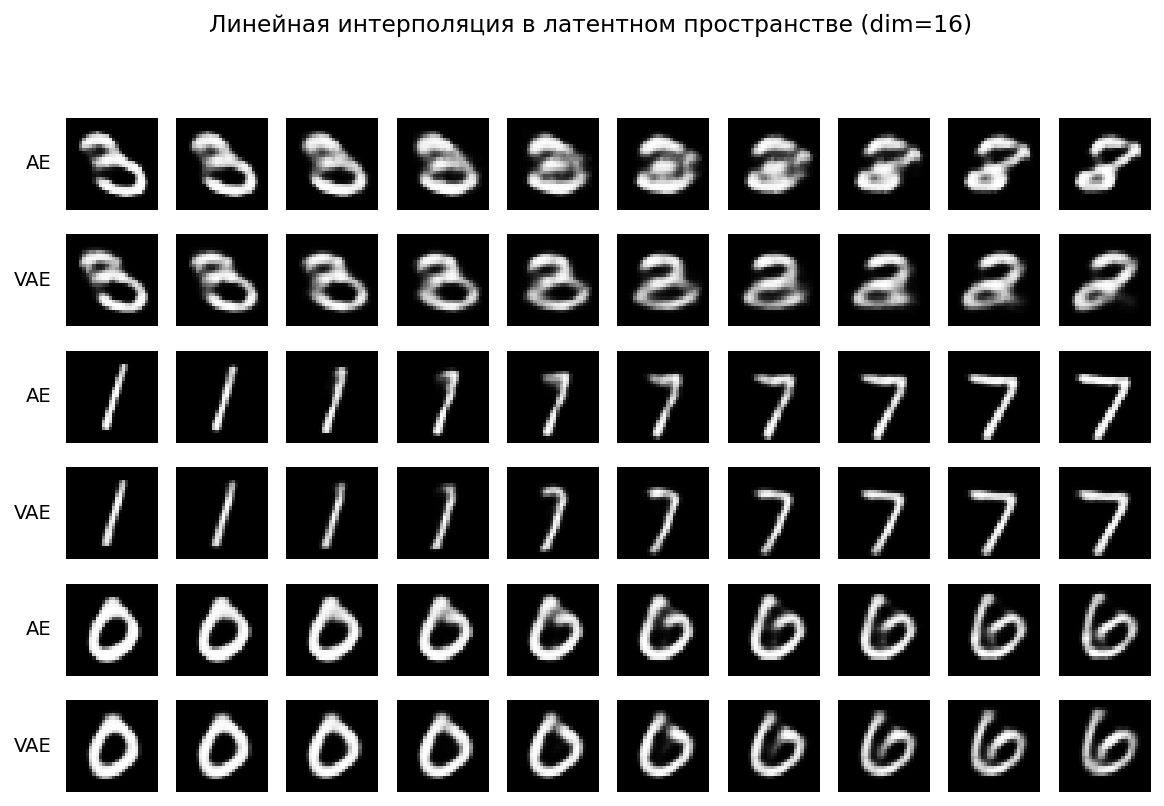

Линейная интерполяция между кодами двух цифр (3->8, 1->7, 0->6): z(t) = (1-t)*z_a + t*z_b. Для VAE берутся значения mu.

- Обе модели переходят между цифрами плавно, через правдоподобные промежуточные формы.
- Кадры VAE в среднем более размытые. В переходе 3->8 конечный кадр VAE не похож на 8 (это ошибка реконструкции, видная и в п. 5.3), а AE сохраняет детали лучше.
- Существенного преимущества VAE в интерполяции по этим примерам не видно. Три пары - это небольшая выборка, поэтому вывод осторожный.

## 6. Сравнение AE и VAE

| Критерий | AE | VAE |
|---|---|---|
| Что кодирует | точку z | распределение (mu, sigma) |
| Loss | BCE | BCE + KL |
| Реконструкция при dim >= 16 | лучше (BCE 67,7 и 58,0) | хуже (BCE 75,9 и 75,1) |
| Реконструкция при dim <= 8 | практически равна VAE | практически равна AE |
| Масштаб латентного пространства | произвольный (до +-30 при dim = 2) | около N(0, I) (до +-4) |
| Генерация из z ~ N(0, I) | не работает | работает |
| Генерация с подгонкой распределения z | работает, больше брака | не требуется |
| Разделимость классов (t-SNE) | хорошая | хорошая |
| Основное применение | сжатие, признаки, denoising, поиск аномалий | генерация, интерполяция, работа с латентным пространством |

## 7. Выводы

1. **Сжатие.** Обе модели сжимают изображение 784 -> 2, 8, 16 или 64 числа (в 392, 98, 49 и 12,25 раза). Чем шире bottleneck, тем меньше ошибка реконструкции.
2. **Реконструкция.** AE восстанавливает изображения точнее, особенно при большом коде: при dim = 64 его BCE 58,0 против 75,1 у VAE, MSE ниже в 2,6 раза. При dim = 2 и 8 различия незначительны. VAE платит потерей точности за регуляризацию KL.
3. **Латентное пространство.** У AE оно не структурировано и имеет произвольный масштаб. У VAE оно компактно и приближено к N(0, I).
4. **Генерация.** VAE порождает узнаваемые цифры из случайного z ~ N(0, I), AE без знания распределения своих кодов - нет. Это главное практическое различие двух подходов.
5. **Выбор модели.** Если нужны только сжатие, признаки, шумоподавление или поиск аномалий, лучше подходит AE (точнее реконструкция). Если нужны генерация новых объектов или работа с непрерывным латентным пространством, нужен VAE.

## 8. Ограничения работы

- Обучение проведено один раз (seed = 0), без повторов и доверительных интервалов, поэтому малые различия (dim = 2 и 8) нельзя считать значимыми.
- Использованы полносвязные сети. Свёрточные архитектуры (как CAE в лекции) дали бы более чёткие изображения.
- Качество генерации и интерполяции оценено визуально, численной метрики (например FID) нет.
- Коэффициент при KL-слагаемом фиксирован и равен 1. Его изменение (beta-VAE) сместило бы баланс между реконструкцией и структурой пространства, но в работе не исследовалось.